In [1]:
import numpy as np
import matplotlib.pyplot as plt
from bat_hd.random_walk import generate_bat_flight, sphere_from_toroid
from bat_hd.bat_hd_system import BatHeadDirectionSystem, BatHDSystemConfig
from bat_hd.plot_tools import smooth_ts, activity_map
import os
from concurrent.futures import ThreadPoolExecutor

DATA_DIR = "../simulation_data/inverted_session"
PLOTS_DIR = "../plots/inverted_session"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)

In [2]:
dt = 0.5e-3
n = 256
intrinsic_noise = 0
input_noise = 0
n_conj = (20, 10)

net_anchor = BatHeadDirectionSystem(
    BatHDSystemConfig(
        input_noise=input_noise,
        intrinsic_noise=intrinsic_noise,
        n_conjunctive=n_conj,
        gravity_gated=True,
    )
)
net_anchor.warm_up()

In [3]:
v_yaw_upright = 30
v_pitch_upright = 0

duration_upright = 360 / v_yaw_upright

t_upright = np.arange(0, duration_upright, step=dt)


angular_velocity_upright = np.stack(
    [
        v_yaw_upright * np.ones_like(t_upright),
        v_pitch_upright * np.ones_like(t_upright),
    ],
    axis=-1,
)
toroid_heading_upright = np.stack(
    [v_yaw_upright * t_upright, v_pitch_upright * t_upright], axis=-1
)
sphere_heading_upright = sphere_from_toroid(toroid_heading_upright)
upright_index = len(t_upright)

v_yaw_flip = 0
v_pitch_flip = 30
duration_flip = 180 / v_pitch_flip

t_flip = np.arange(0, duration_flip, step=dt)
angular_velocity_flip = np.stack(
    [v_yaw_flip * np.ones_like(t_flip), v_pitch_flip * np.ones_like(t_flip)], axis=-1
)
toroid_heading_flip = np.stack([v_yaw_flip * t_flip, v_pitch_flip * t_flip], axis=-1)
sphere_heading_flip = sphere_from_toroid(toroid_heading_flip)
t_flip = t_flip + duration_upright
flip_index = len(t_flip)


v_yaw_inverted = 30
v_pitch_inverted = 0
duration_inverted = 2 * 180 / v_yaw_inverted

t_inverted = np.arange(0, duration_inverted, step=dt)
angular_velocity_inverted = np.stack(
    [
        v_yaw_inverted * np.ones_like(t_inverted),
        v_pitch_inverted * np.ones_like(t_inverted),
    ],
    axis=-1,
)
toroid_heading_inverted = np.stack(
    [v_yaw_inverted * t_inverted, 180 + v_pitch_inverted * t_inverted], axis=-1
)
sphere_heading_inverted = sphere_from_toroid(toroid_heading_inverted)
t_inverted = t_inverted + duration_upright + duration_flip
inverted_index = len(t_inverted) + flip_index


toroid_heading = np.concatenate(
    [toroid_heading_upright, toroid_heading_flip, toroid_heading_inverted], axis=0
)
sphere_heading = np.concatenate(
    [sphere_heading_upright, sphere_heading_flip, sphere_heading_inverted], axis=0
) + np.array([180, 0])
inversion = toroid_heading[..., 1] > 90
angular_velocity = np.concatenate(
    [angular_velocity_upright, angular_velocity_flip, angular_velocity_inverted], axis=0
)

In [5]:
recording = net_anchor.run_simulation({"dir_vel": angular_velocity, "inverted":inversion})

Running Simulation Steps: 100%|██████████| 60000/60000 [00:09<00:00, 6442.80it/s]


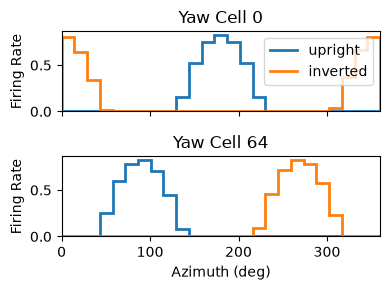

In [18]:
cell_indices = [0, 64]
fig, axes = plt.subplots(len(cell_indices),1, figsize=(4, 1.5  * len(cell_indices)), sharex=True)

for ax, cell_index in zip(axes, cell_indices):
    upright_map, upright_counts, upright_edges = activity_map(
        sphere_heading[:upright_index, 0],
        recording["yaw_cells"][:upright_index, cell_index],
    )
    inverted_map, inverted_counts, inverted_edges = activity_map(
        sphere_heading[inverted_index:, 0],
        recording["yaw_cells"][inverted_index:, cell_index],
    )
    ax.stairs(upright_map, upright_edges[0], label="upright", color="C0", lw=2)
    ax.stairs(inverted_map, inverted_edges[0], label="inverted", color="C1", lw=2)
    ax.set_ylabel("Firing Rate")
    ax.set_xlim(inverted_edges[0][[0, -1]])
    ax.set_title(f"Yaw Cell {cell_index}")

axes[-1].set_xlabel("Azimuth (deg)")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles, labels, loc="upper right")

fig.tight_layout()
fig.savefig(os.path.join(PLOTS_DIR, f"yaw_cell_{cell_index}_activity_map.svg"))

In [7]:
v_yaw_full_turn = 0
v_pitch_full_turn = 30

duration = 2 * 180 / v_pitch_full_turn

t_session = np.arange(0, duration, step=dt)


angular_velocity_full_turn = np.stack(
    [
        v_yaw_full_turn * np.ones_like(t_session),
        v_pitch_full_turn * np.ones_like(t_session),
    ],
    axis=-1,
)
toroid_heading_full_turn = np.stack(
    [
        v_yaw_full_turn * t_session,
        (v_pitch_full_turn * t_session + 180 - 180 / 2) % (2 * 180) - 180,
    ],
    axis=-1,
)
sphere_heading_full_turn = sphere_from_toroid(toroid_heading_full_turn)

toroid_heading_full_turn = toroid_heading_full_turn
sphere_heading_full_turn = sphere_heading_full_turn + np.array([0, 0])
inversion_full_turn = np.abs(toroid_heading_full_turn[..., 1]) > 90

In [10]:
recording_full_turn = net_anchor.run_simulation(
    {"dir_vel": angular_velocity_full_turn, "inverted": inversion_full_turn}
)

Running Simulation Steps: 100%|██████████| 24000/24000 [00:04<00:00, 5826.45it/s]


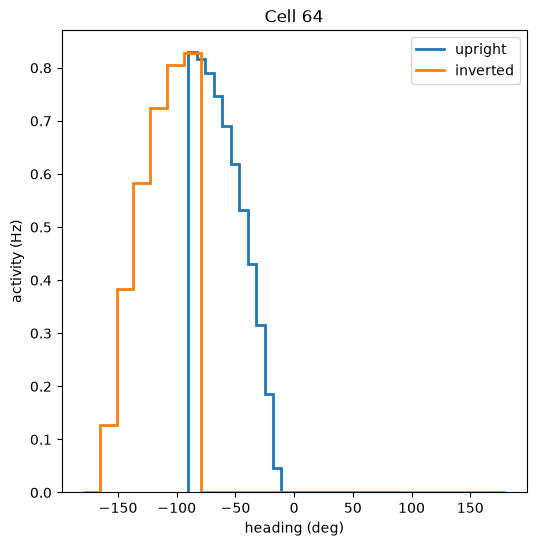

In [11]:
cell_index = 64
fig, ax = plt.subplots(1, 1, figsize=(6, 6))
upright_map, upright_counts, upright_edges = activity_map(
    toroid_heading_full_turn[~inversion_full_turn, 1],
    recording_full_turn["pitch_cells"][~inversion_full_turn, cell_index],
)
inverted_map, inverted_counts, inverted_edges = activity_map(
    toroid_heading_full_turn[inversion_full_turn, 1],
    recording_full_turn["pitch_cells"][inversion_full_turn, cell_index],
)
ax.stairs(upright_map, upright_edges[0], label="upright", color="C0", lw=2)
ax.stairs(inverted_map, inverted_edges[0], label="inverted", color="C1", lw=2)
ax.set_xlabel("heading (deg)")
ax.set_ylabel("activity (Hz)")
ax.set_title(f"Cell {cell_index}")
ax.legend()
fig.savefig(os.path.join(PLOTS_DIR, f"pitch_cell_{cell_index}_activity_map.svg"))